**I. Data Preparation**

In [ ]:
from google.colab import files
import pandas as pd
uploaded = files.upload()


Saving updated_sbpr_data_table_en_may2026.csv to updated_sbpr_data_table_en_may2026 (1).csv


In [ ]:
import pandas as pd
df = pd.read_csv(
    "updated_sbpr_data_table_en_may2026.csv",
    encoding="cp1252"
)
df.head()

,Board Number,Board Name,Board Language,Board Type,Region,City,Grade 10 OSSLT Results,Progress in Grade 10 OSSLT Results,Credit Accumulation by the end of Grade 10,Progress in Credit Accumulation by the end of Grade 10,Credit Accumulation by the end of Grade 11,Progress in Credit Accumulation by the end of Grade 11,Four Year Graduation Rate 2020-2021 Grade 9 Cohort,Progress in Four Year Graduation Rate 2020-2021 Grade 9 Cohort,Five Year Graduation Rate 2019-2020 Grade 9 Cohort,Progress in Five Year Graduation Rate 2019-2020 Grade 9 Cohort
0,B28010,Algoma DSB,English,Public,North Region,Sault Ste Marie,0.73,0.01,0.72,0.02,0.77,0.02,0.738,0.029,0.775,0.015
1,B67202,Algonquin and Lakeshore CDSB,English,Roman Catholic,East Region,Napanee,0.86,0.00,0.84,0.03,0.88,0.01,0.914,0.032,0.926,0.003
2,B66010,Avon Maitland DSB,English,Public,West Region,Seaforth,0.81,0.00,0.79,0.03,0.78,0.01,0.784,-0.022,0.861,-0.007
3,B66001,Bluewater DSB,English,Public,West Region,Chesley,0.82,0.07,0.70,0.06,0.70,0.01,0.725,0.024,0.852,0.028
4,B67164,Brant Haldimand Norfolk CDSB,English,Roman Catholic,West Region,Brantford,0.89,0.04,0.80,0.04,0.85,0.04,0.841,-0.015,0.873,0.005


**a. Cleaning the Column Names**

In [ ]:
# 1. Clean column names first
df.columns = (
    df.columns
      .str.replace("\xa0", " ", regex=False)   # remove non-breaking spaces
      .str.replace(r"\s+", " ", regex=True)    # collapse repeated spaces
      .str.strip()
)

# See all column names
for col in df.columns:
    print(repr(col))

'Board_Number'
'Board_Name'
'Board_Language'
'Board_Type'
'Region'
'City'
'Grade10_OSSLT'
'Progress in Grade 10 OSSLT Results'
'Grade10_Credits'
'Progress in Credit Accumulation by the end of Grade 10'
'Grade11_Credits'
'Progress in Credit Accumulation by the end of Grade 11'
'Four Year Graduation Rate 2020-2021 Grade 9 Cohort'
'Progress in Four Year Graduation Rate 2020-2021 Grade 9 Cohort'
'Five Year Graduation Rate 2019-2020 Grade 9 Cohort'
'Progress in Five Year Graduation Rate 2019-2020 Grade 9 Cohort'


In [ ]:
[col for col in df.columns if "Graduation" in col]

['Four Year Graduation Rate 2020-2021 Grade 9 Cohort',
 'Progress in Four Year Graduation Rate 2020-2021 Grade 9 Cohort',
 'Five Year Graduation Rate 2019-2020 Grade 9 Cohort',
 'Progress in Five Year Graduation Rate 2019-2020 Grade 9 Cohort']

In [ ]:
graduation_cols = [
    col for col in df.columns
    if "Five Year Graduation Rate" in col
    and "Progress" not in col
]
print(graduation_cols)

['Five Year Graduation Rate 2019-2020 Grade 9 Cohort']


In [ ]:
graduation_col = graduation_cols[0]

df = df.rename(columns={
    graduation_col: "FiveYear_Graduation"
})
print("FiveYear_Graduation" in df.columns)

True


**b. Extracting Provincial Benchmark**

In [ ]:
province_row = df[
    (df["Board_Name"] == "Province") &
    (df["Board_Language"] == "English/French")
]
provincial_benchmark = province_row["FiveYear_Graduation"].iloc[0]
print("Provincial benchmark:", provincial_benchmark)
print("Provincial benchmark (%):", provincial_benchmark * 100)

Provincial benchmark: 0.895
Provincial benchmark (%): 89.5


In [ ]:
df.columns = (
    df.columns
      .str.replace("\xa0", " ", regex=False)
      .str.replace(r"\s+", " ", regex=True)
      .str.strip()
)
graduation_cols = [
    col for col in df.columns
    if "Five Year Graduation Rate" in col
    and "Progress" not in col
]

print("Graduation column found:", graduation_cols)
if len(graduation_cols) == 1:
    df = df.rename(
        columns={graduation_cols[0]: "FiveYear_Graduation"}
    )
else:
    print("Please inspect the graduation columns.")
print("FiveYear_Graduation" in df.columns)

Graduation column found: []
Please inspect the graduation columns.
True


**c. Selecting Relevant Variables**

In [ ]:
selected_columns = [
    "Board_Number",
    "Board_Name",
    "Board_Language",
    "Board_Type",
    "Region",
    "City",
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]
data = df[selected_columns].copy()
data.head()

,Board_Number,Board_Name,Board_Language,Board_Type,Region,City,Grade10_OSSLT,Grade10_Credits,Grade11_Credits,FiveYear_Graduation
0,B28010,Algoma DSB,English,Public,North Region,Sault Ste Marie,0.73,0.72,0.77,0.775
1,B67202,Algonquin and Lakeshore CDSB,English,Roman Catholic,East Region,Napanee,0.86,0.84,0.88,0.926
2,B66010,Avon Maitland DSB,English,Public,West Region,Seaforth,0.81,0.79,0.78,0.861
3,B66001,Bluewater DSB,English,Public,West Region,Chesley,0.82,0.70,0.70,0.852
4,B67164,Brant Haldimand Norfolk CDSB,English,Roman Catholic,West Region,Brantford,0.89,0.80,0.85,0.873


**d. Removing Provincial Aggregate Rows**

In [ ]:
data = data[data["Board_Name"] != "Province"].copy()
print("Shape after removing provincial rows:", data.shape)

Shape after removing provincial rows: (76, 10)


**e. Standardizing Missing Values**

In [ ]:
import numpy as np
data = data.replace(
    ["N/A", "NA", "-", "", " "],
    np.nan
)

In [ ]:
numeric_columns = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]
for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

**f. Checking Missing Values**

In [ ]:
missing_summary = data.isna().sum()
print(missing_summary)

Board_Number           4
Board_Name             4
Board_Language         4
Board_Type             4
Region                 4
City                   4
Grade10_OSSLT          6
Grade10_Credits        6
Grade11_Credits        6
FiveYear_Graduation    6
dtype: int64


In [ ]:
missing_table = pd.DataFrame({
    "Missing_Count": data.isna().sum(),
    "Missing_Percent": (
        data.isna().mean() * 100
    ).round(2)
})
missing_table

,Missing_Count,Missing_Percent
Board_Number,4,5.26
Board_Name,4,5.26
Board_Language,4,5.26
Board_Type,4,5.26
Region,4,5.26
City,4,5.26
Grade10_OSSLT,6,7.89
Grade10_Credits,6,7.89
Grade11_Credits,6,7.89
FiveYear_Graduation,6,7.89


In [ ]:
incomplete_boards = data[
    data[numeric_columns].isna().any(axis=1)
]

incomplete_boards[
    ["Board_Name"] + numeric_columns
]

,Board_Name,Grade10_OSSLT,Grade10_Credits,Grade11_Credits,FiveYear_Graduation
44,Northwest CDSB,NaN,NaN,NaN,NaN
57,Superior North CDSB,NaN,NaN,NaN,NaN
75,NaN,NaN,NaN,NaN,NaN
76,NaN,NaN,NaN,NaN,NaN
77,NaN,NaN,NaN,NaN,NaN
78,NaN,NaN,NaN,NaN,NaN


**g. Removing Incomplete Core Records**

In [ ]:
clean_data = data.dropna(
    subset=numeric_columns
).copy()
print("Clean dataset shape:", clean_data.shape)

Clean dataset shape: (70, 10)


**h. Checking Duplicates**

In [ ]:
print(
    "Duplicate board numbers:",
    clean_data["Board_Number"].duplicated().sum()
)
print(
    "Duplicate board names:",
    clean_data["Board_Name"].duplicated().sum()
)

Duplicate board numbers: 0
Duplicate board names: 0


**i. Validating Numeric Ranges**

In [ ]:
for col in numeric_columns:
    invalid = clean_data[
        (clean_data[col] < 0) |
        (clean_data[col] > 1)
    ]
    print(
        col,
        "invalid values:",
        len(invalid)
    )

Grade10_OSSLT invalid values: 0
Grade10_Credits invalid values: 0
Grade11_Credits invalid values: 0
FiveYear_Graduation invalid values: 0


In [ ]:
clean_data[numeric_columns].agg(
    ["min", "max", "mean", "median", "std"]
)

,Grade10_OSSLT,Grade10_Credits,Grade11_Credits,FiveYear_Graduation
min,0.570000,0.630000,0.650000,0.690000
max,0.970000,0.950000,0.950000,0.974000
mean,0.840000,0.807286,0.831000,0.875329
median,0.845000,0.810000,0.845000,0.883000
std,0.067566,0.075314,0.070878,0.061758


**j. Cleaning Categorial Variables**

In [ ]:
categorical_columns = [
    "Board_Language",
    "Board_Type",
    "Region",
    "City"
]

for col in categorical_columns:
    clean_data[col] = (
        clean_data[col]
        .astype(str)
        .str.strip()
    )

In [ ]:
for col in [
    "Board_Language",
    "Board_Type",
    "Region"
]:
    print("\n", col)
    print(clean_data[col].value_counts())


 Board_Language
Board_Language
English    58
French     12
Name: count, dtype: int64

 Board_Type
Board_Type
Public            35
Roman Catholic    35
Name: count, dtype: int64

 Region
Region
West Region       21
North Region      20
East Region       16
Central Region     9
Toronto Region     4
Name: count, dtype: int64


**k. Creating Binary Target**

In [ ]:
clean_data["Below_Benchmark"] = np.where(
    clean_data["FiveYear_Graduation"]
    < provincial_benchmark,
    1,
    0
)

In [ ]:
class_counts = (
    clean_data["Below_Benchmark"]
    .value_counts()
    .sort_index()
)
print(class_counts)

Below_Benchmark
0    30
1    40
Name: count, dtype: int64


In [ ]:
class_percent = (
    clean_data["Below_Benchmark"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)
print(class_percent.round(1))

Below_Benchmark
0    42.9
1    57.1
Name: proportion, dtype: float64


**l. Displaying Variables**

In [ ]:
clean_data["OSSLT_Percent"] = (
    clean_data["Grade10_OSSLT"] * 100
)
clean_data["Grade10_Credits_Percent"] = (
    clean_data["Grade10_Credits"] * 100
)
clean_data["Grade11_Credits_Percent"] = (
    clean_data["Grade11_Credits"] * 100
)
clean_data["Graduation_Percent"] = (
    clean_data["FiveYear_Graduation"] * 100
)
display_columns = [
    "Board_Name",
    "OSSLT_Percent",
    "Grade10_Credits_Percent",
    "Grade11_Credits_Percent",
    "Graduation_Percent"
]
clean_data[display_columns].head(10)

,Board_Name,OSSLT_Percent,Grade10_Credits_Percent,Grade11_Credits_Percent,Graduation_Percent
0,Algoma DSB,73.0,72.0,77.0,77.5
1,Algonquin and Lakeshore CDSB,86.0,84.0,88.0,92.6
2,Avon Maitland DSB,81.0,79.0,78.0,86.1
3,Bluewater DSB,82.0,70.0,70.0,85.2
4,Brant Haldimand Norfolk CDSB,89.0,80.0,85.0,87.3
5,Bruce-Grey CDSB,84.0,81.0,85.0,93.0
6,CDSB of Eastern Ontario,83.0,88.0,86.0,89.9
7,CÉP de l'Est de l'Ontario,94.0,71.0,87.0,91.9
8,Conseil scolaire catholique Providence,90.0,95.0,95.0,97.4
9,CS catholique MonAvenir,94.0,93.0,93.0,94.5


In [ ]:
Grade10_OSSLT = 0.85

**m. Quality Check**

In [ ]:
print("Number of observations:",
      len(clean_data))
print("\nMissing values:")
print(
    clean_data[
        numeric_columns
        + ["Below_Benchmark"]
    ].isna().sum()
)
print("\nTarget distribution:")
print(
    clean_data[
        "Below_Benchmark"
    ].value_counts()
)
print("\nNumeric summary:")
print(
    clean_data[
        numeric_columns
    ].describe()
)

Number of observations: 70

Missing values:
Grade10_OSSLT          0
Grade10_Credits        0
Grade11_Credits        0
FiveYear_Graduation    0
Below_Benchmark        0
dtype: int64

Target distribution:
Below_Benchmark
1    40
0    30
Name: count, dtype: int64

Numeric summary:
       Grade10_OSSLT  Grade10_Credits  Grade11_Credits  FiveYear_Graduation
count      70.000000        70.000000        70.000000            70.000000
mean        0.840000         0.807286         0.831000             0.875329
std         0.067566         0.075314         0.070878             0.061758
min         0.570000         0.630000         0.650000             0.690000
25%         0.810000         0.750000         0.782500             0.836000
50%         0.845000         0.810000         0.845000             0.883000
75%         0.880000         0.860000         0.880000             0.923750
max         0.970000         0.950000         0.950000             0.974000


**n. Data Correction**

In [ ]:
numeric_columns = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]

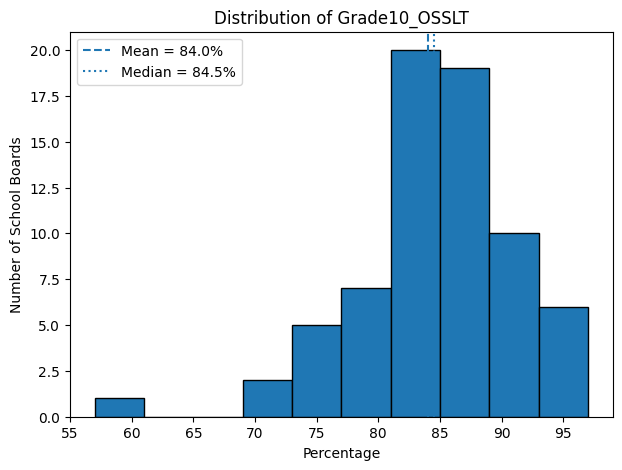

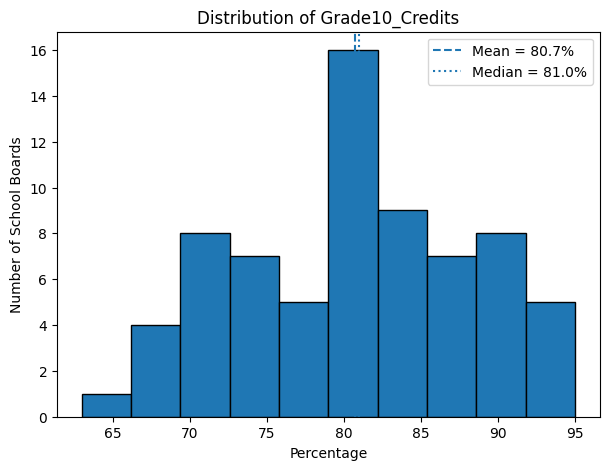

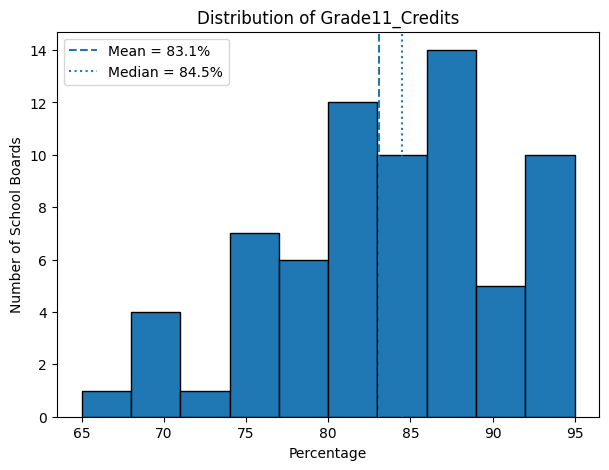

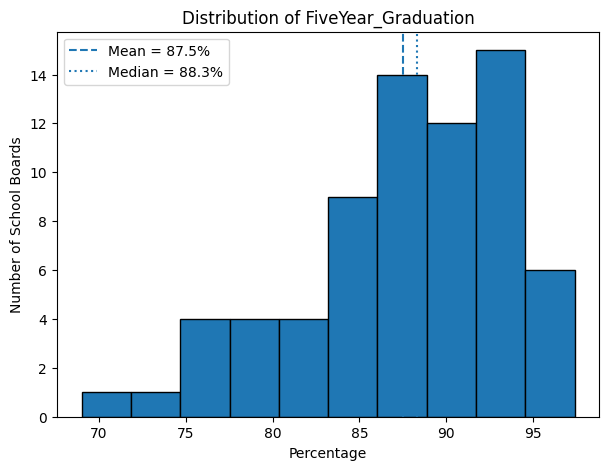

In [ ]:
import matplotlib.pyplot as plt
for col in numeric_columns:
    values = clean_data[col] * 100
    plt.figure(figsize=(7, 5))
    plt.hist(values, bins=10, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel("Percentage")
    plt.ylabel("Number of School Boards")
    plt.axvline(
        values.mean(),
        linestyle="--",
        label=f"Mean = {values.mean():.1f}%"
    )
    plt.axvline(
        values.median(),
        linestyle=":",
        label=f"Median = {values.median():.1f}%"
    )
    plt.legend()
    plt.show()

In [ ]:
skewness = clean_data[numeric_columns].skew()
print(skewness)

Grade10_OSSLT         -1.006708
Grade10_Credits       -0.161504
Grade11_Credits       -0.389208
FiveYear_Graduation   -0.780740
dtype: float64


In [ ]:
clean_data.to_csv(
    "ontario_school_boards_clean.csv",
    index=False
)
clean_data.to_excel(
    "ontario_school_boards_clean.xlsx",
    index=False
)

**II. Univariate and Bivariate Analysis**

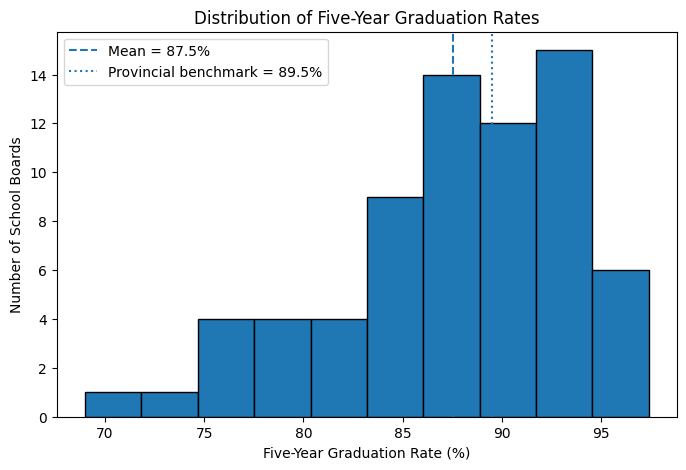

In [ ]:
import matplotlib.pyplot as plt
graduation = clean_data["FiveYear_Graduation"] * 100
plt.figure(figsize=(8, 5))
plt.hist(
    graduation,
    bins=10,
    edgecolor="black"
)
plt.axvline(
    graduation.mean(),
    linestyle="--",
    label=f"Mean = {graduation.mean():.1f}%"
)
plt.axvline(
    provincial_benchmark * 100,
    linestyle=":",
    label=f"Provincial benchmark = {provincial_benchmark * 100:.1f}%"
)
plt.title("Distribution of Five-Year Graduation Rates")
plt.xlabel("Five-Year Graduation Rate (%)")
plt.ylabel("Number of School Boards")
plt.legend()
plt.show()

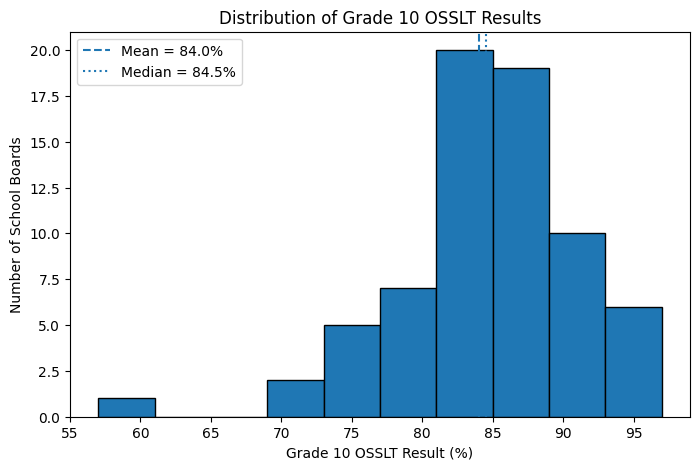

In [ ]:
osslt = clean_data["Grade10_OSSLT"] * 100
plt.figure(figsize=(8, 5))
plt.hist(
    osslt,
    bins=10,
    edgecolor="black"
)
plt.axvline(
    osslt.mean(),
    linestyle="--",
    label=f"Mean = {osslt.mean():.1f}%"
)
plt.axvline(
    osslt.median(),
    linestyle=":",
    label=f"Median = {osslt.median():.1f}%"
)
plt.title("Distribution of Grade 10 OSSLT Results")
plt.xlabel("Grade 10 OSSLT Result (%)")
plt.ylabel("Number of School Boards")
plt.legend()
plt.show()

/tmp/ipykernel_2167/2603238783.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


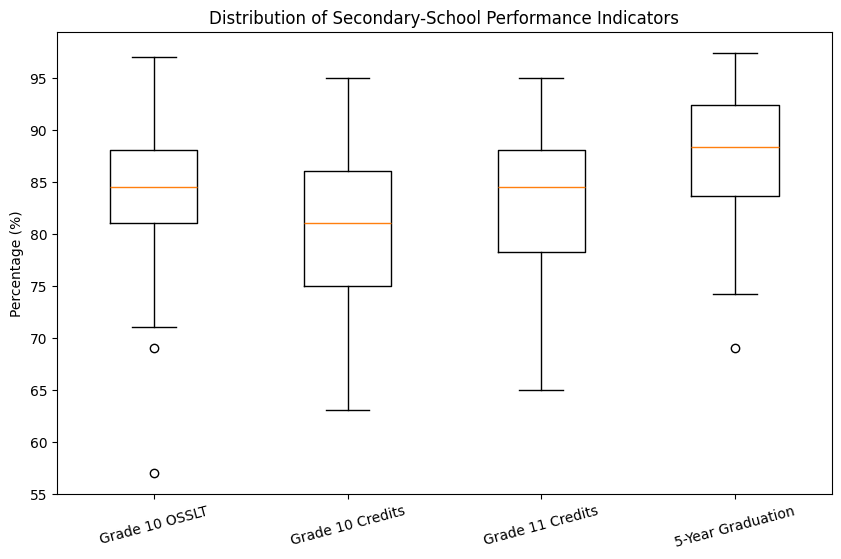

In [ ]:
numeric_columns = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]
boxplot_data = clean_data[numeric_columns] * 100
plt.figure(figsize=(10, 6))
plt.boxplot(
    boxplot_data,
    labels=[
        "Grade 10 OSSLT",
        "Grade 10 Credits",
        "Grade 11 Credits",
        "5-Year Graduation"
    ]
)
plt.title("Distribution of Secondary-School Performance Indicators")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15)
plt.show()

In [ ]:
frequency_table = pd.DataFrame({
    "Frequency": clean_data["Below_Benchmark"]
        .value_counts()
        .sort_index(),
    "Percentage": clean_data["Below_Benchmark"]
        .value_counts(normalize=True)
        .sort_index() * 100
})
frequency_table.index = [
    "At or Above Benchmark",
    "Below Benchmark"
]
frequency_table["Percentage"] = (
    frequency_table["Percentage"]
    .round(1)
)
frequency_table

,Frequency,Percentage
At or Above Benchmark,30,42.9
Below Benchmark,40,57.1


In [ ]:
clean_data

,Board_Number,Board_Name,Board_Language,Board_Type,Region,City,Grade10_OSSLT,Grade10_Credits,Grade11_Credits,FiveYear_Graduation,Below_Benchmark,OSSLT_Percent,Grade10_Credits_Percent,Grade11_Credits_Percent,Graduation_Percent,Grade10_OSSLT_log,Grade10_Credits_log,Grade11_Credits_log
0,B28010,Algoma DSB,English,Public,North Region,Sault Ste Marie,0.73,0.72,0.77,0.775,1,73.0,72.0,77.0,77.5,-0.314711,-0.328504,-0.261365
1,B67202,Algonquin and Lakeshore CDSB,English,Roman Catholic,East Region,Napanee,0.86,0.84,0.88,0.926,0,86.0,84.0,88.0,92.6,-0.150823,-0.174353,-0.127833
2,B66010,Avon Maitland DSB,English,Public,West Region,Seaforth,0.81,0.79,0.78,0.861,1,81.0,79.0,78.0,86.1,-0.210721,-0.235722,-0.248461
3,B66001,Bluewater DSB,English,Public,West Region,Chesley,0.82,0.70,0.70,0.852,1,82.0,70.0,70.0,85.2,-0.198451,-0.356675,-0.356675
4,B67164,Brant Haldimand Norfolk CDSB,English,Roman Catholic,West Region,Brantford,0.89,0.80,0.85,0.873,1,89.0,80.0,85.0,87.3,-0.116534,-0.223144,-0.162519
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,B66176,Waterloo Region DSB,English,Public,West Region,Kitchener,0.85,0.81,0.81,0.875,1,85.0,81.0,81.0,87.5,-0.162519,-0.210721,-0.210721
68,B67130,Wellington CDSB,English,Roman Catholic,West Region,Guelph,0.85,0.87,0.86,0.894,1,85.0,87.0,86.0,89.4,-0.162519,-0.139262,-0.150823
69,B67024,Windsor-Essex CDSB,English,Roman Catholic,West Region,Windsor,0.94,0.86,0.88,0.928,0,94.0,86.0,88.0,92.8,-0.061875,-0.150823,-0.127833
70,B67075,York CDSB,English,Roman Catholic,Central Region,Aurora,0.90,0.90,0.94,0.972,0,90.0,90.0,94.0,97.2,-0.105361,-0.105361,-0.061875


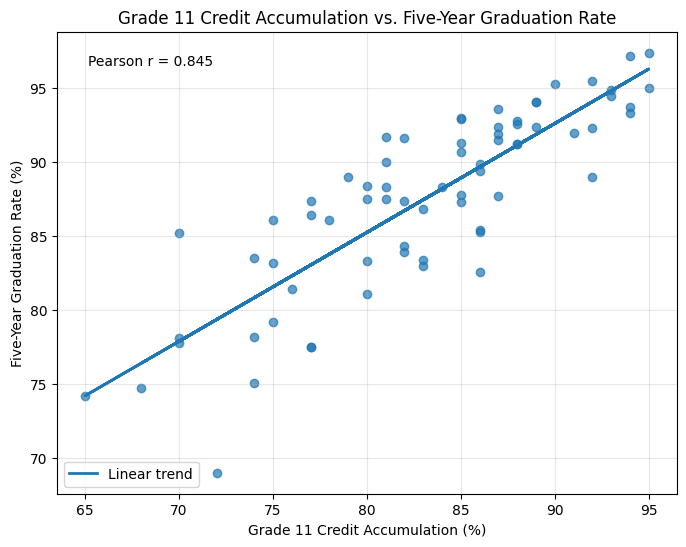

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Convert proportions to percentages
x = clean_data["Grade11_Credits"] * 100
y = clean_data["FiveYear_Graduation"] * 100

# Calculate Pearson correlation
correlation = x.corr(y)

# Regression line
slope, intercept = np.polyfit(x, y, 1)
regression_line = slope * x + intercept

# Plot
plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    alpha=0.7
)

plt.plot(
    x,
    regression_line,
    linewidth=2,
    label="Linear trend"
)

plt.title(
    "Grade 11 Credit Accumulation vs. Five-Year Graduation Rate"
)

plt.xlabel(
    "Grade 11 Credit Accumulation (%)"
)

plt.ylabel(
    "Five-Year Graduation Rate (%)"
)

plt.text(
    0.05,
    0.95,
    f"Pearson r = {correlation:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
correlation_variables = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]
corr_matrix = (
    clean_data[correlation_variables]
    .corr()
)
corr_matrix

,Grade10_OSSLT,Grade10_Credits,Grade11_Credits,FiveYear_Graduation
Grade10_OSSLT,1.000000,0.647070,0.712996,0.744999
Grade10_Credits,0.647070,1.000000,0.837813,0.727537
Grade11_Credits,0.712996,0.837813,1.000000,0.845239
FiveYear_Graduation,0.744999,0.727537,0.845239,1.000000


In [ ]:
clean_data["Benchmark_Group"] = (
    clean_data["Below_Benchmark"]
    .map({
        1: "Below Benchmark",
        0: "At/Above Benchmark"
    })
)

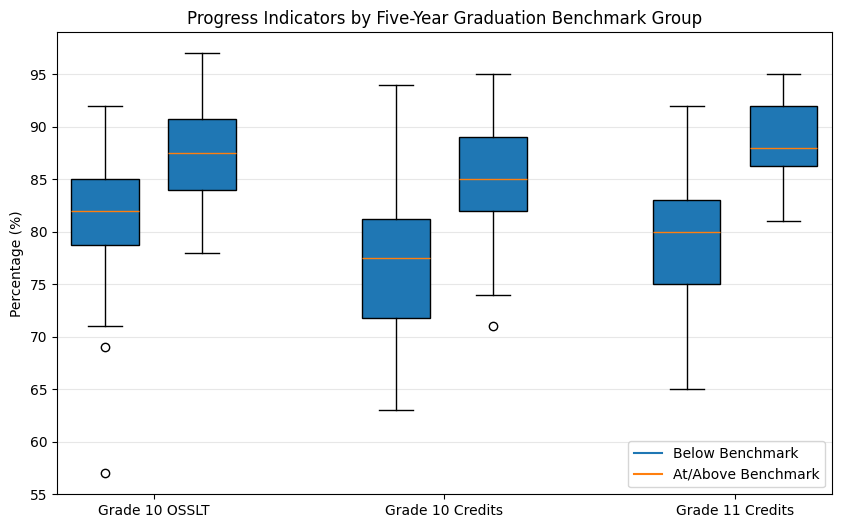

In [ ]:
indicators = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits"
]

indicator_labels = [
    "Grade 10 OSSLT",
    "Grade 10 Credits",
    "Grade 11 Credits"
]

below_data = [
    clean_data.loc[
        clean_data["Below_Benchmark"] == 1,
        col
    ] * 100
    for col in indicators
]

above_data = [
    clean_data.loc[
        clean_data["Below_Benchmark"] == 0,
        col
    ] * 100
    for col in indicators
]

plt.figure(figsize=(10, 6))

positions_below = [1, 4, 7]
positions_above = [2, 5, 8]

bp1 = plt.boxplot(
    below_data,
    positions=positions_below,
    widths=0.7,
    patch_artist=True
)
bp2 = plt.boxplot(
    above_data,
    positions=positions_above,
    widths=0.7,
    patch_artist=True
)
plt.xticks(
    [1.5, 4.5, 7.5],
    indicator_labels
)
plt.ylabel("Percentage (%)")
plt.title(
    "Progress Indicators by Five-Year Graduation Benchmark Group"
)
plt.plot(
    [],
    [],
    label="Below Benchmark"
)
plt.plot(
    [],
    [],
    label="At/Above Benchmark"
)
plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)
plt.show()

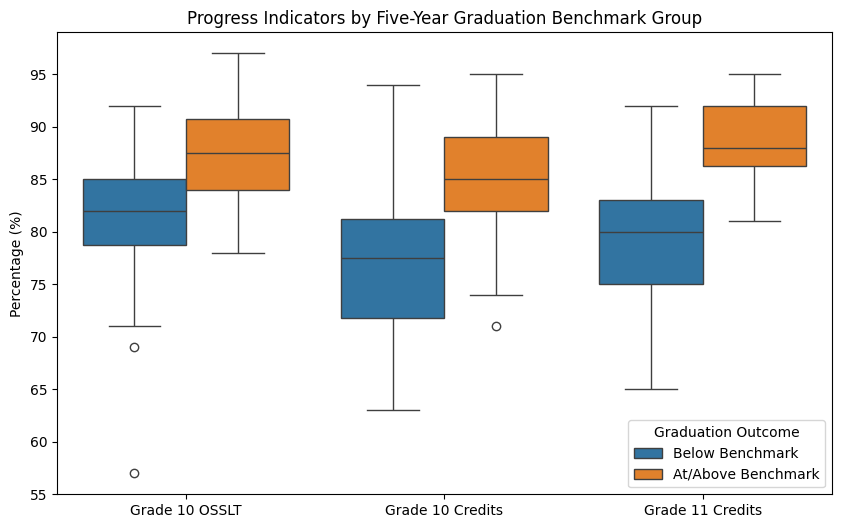

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

plot_data = clean_data[
    [
        "Below_Benchmark",
        "Grade10_OSSLT",
        "Grade10_Credits",
        "Grade11_Credits"
    ]
].copy()

plot_data["Benchmark_Group"] = (
    plot_data["Below_Benchmark"]
    .map({
        1: "Below Benchmark",
        0: "At/Above Benchmark"
    })
)

plot_data = plot_data.melt(
    id_vars="Benchmark_Group",
    value_vars=[
        "Grade10_OSSLT",
        "Grade10_Credits",
        "Grade11_Credits"
    ],
    var_name="Indicator",
    value_name="Percentage"
)

plot_data["Percentage"] *= 100

plot_data["Indicator"] = (
    plot_data["Indicator"]
    .replace({
        "Grade10_OSSLT": "Grade 10 OSSLT",
        "Grade10_Credits": "Grade 10 Credits",
        "Grade11_Credits": "Grade 11 Credits"
    })
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_data,
    x="Indicator",
    y="Percentage",
    hue="Benchmark_Group"
)

plt.title(
    "Progress Indicators by Five-Year Graduation Benchmark Group"
)

plt.xlabel("")
plt.ylabel("Percentage (%)")

plt.legend(
    title="Graduation Outcome"
)

plt.show()

In [ ]:
group_means = (
    clean_data
    .groupby("Benchmark_Group")[
        [
            "Grade10_OSSLT",
            "Grade10_Credits",
            "Grade11_Credits"
        ]
    ]
    .mean()
    * 100
)

group_means.round(1)

,Grade10_OSSLT,Grade10_Credits,Grade11_Credits
Benchmark_Group,,,
At/Above Benchmark,87.7,84.9,88.7
Below Benchmark,81.2,77.6,78.9
